# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

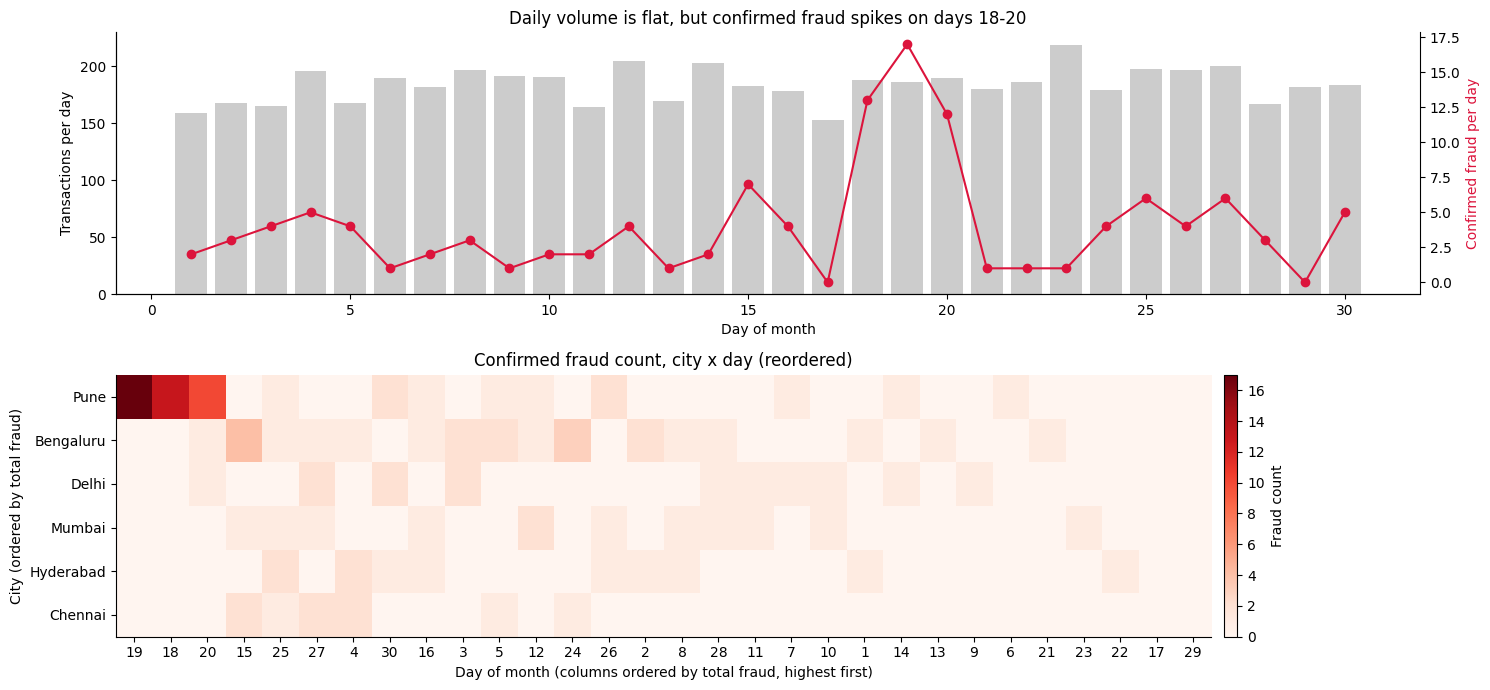

Top (city, day) cells by confirmed fraud:
               fraud
city      day       
Pune      19      17
          18      13
          20      10
Bengaluru 15       4
          24       3


In [2]:

fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1: daily transaction counts (bars) + daily confirmed fraud (line, second axis)
daily = tx.groupby("day").agg(n=("txn_id", "size"), fraud=("is_fraud", "sum"))
axes[0].bar(daily.index, daily.n, color="0.8", label="Transactions")
axes[0].set_xlabel("Day of month"); axes[0].set_ylabel("Transactions per day")
ax2 = axes[0].twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(daily.index, daily.fraud, "-o", color="crimson", label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud per day", color="crimson")
axes[0].set_title("Daily volume is flat, but confirmed fraud spikes on days 18-20")

# TODO 2: city x day matrix of confirmed-fraud counts, rows/columns reordered by their totals
mat = tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id", aggfunc="count", fill_value=0)
mat = mat.reindex(columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0)
heat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index,
               mat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("Day of month (columns ordered by total fraud, highest first)"); axes[1].set_ylabel("City (ordered by total fraud)")
axes[1].set_title("Confirmed fraud count, city x day (reordered)")
fig.colorbar(im, ax=axes[1], label="Fraud count", pad=0.01)

plt.tight_layout(); plt.show()

# TODO 3: the (city, day) cells with the most fraud
top = heat.stack().sort_values(ascending=False).head(5)
print("Top (city, day) cells by confirmed fraud:")
print(top.rename("fraud").to_frame().to_string())


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ The overview showed that the fraud is **concentrated in one city on three consecutive days**: Pune on days 18, 19 and 20 had 13, 17 and 10 confirmed frauds (almost all of those days' 13, 17 and 12 totals), while daily transaction volume stayed flat at about 150-220. A list sorted by detector score treats every alert as an independent row, so it cannot show that the alerts cluster in a place and a time window. Aggregating into a city × day matrix and **reordering rows and columns by their totals** (the reordered matrix of Slide 39, used as an overview-first view, Slide 30) pushes the hot cells into one corner where the pattern is obvious.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

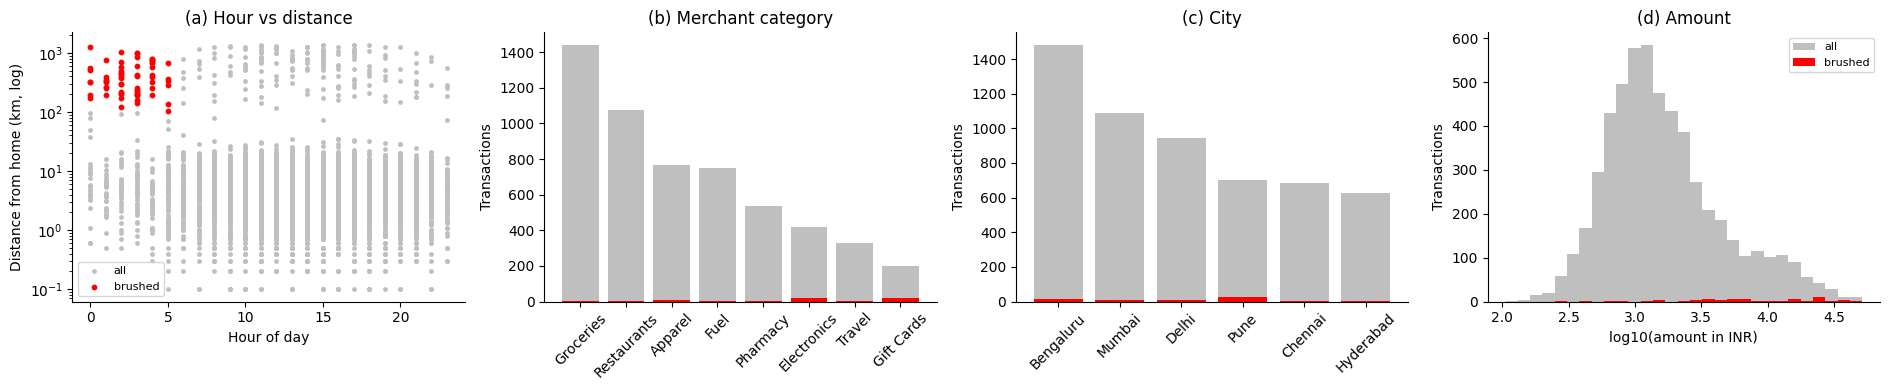

Brushed: 61 transactions (1.1% of all)
Fraud rate inside brush: 86.9% vs overall 2.2% (40x)
Share of ALL fraud captured by the brush: 44.2% (53 of 120)


In [3]:

# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
# (a) hour vs distance (log y)
axes[0].scatter(tx.hour[~brush], tx.distance_from_home_km[~brush], s=6, c="0.75", label="all")
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=10, c="red", label="brushed")
axes[0].set_yscale("log"); axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Distance from home (km, log)")
axes[0].set_title("(a) Hour vs distance"); axes[0].legend(loc="lower left", fontsize=8)
# (b) merchant category counts, (c) city counts
for ax, col, title in [(axes[1], "merchant_category", "(b) Merchant category"), (axes[2], "city", "(c) City")]:
    order = tx[col].value_counts().index
    ax.bar(order, tx[col].value_counts()[order], color="0.75")
    ax.bar(order, tx[brush][col].value_counts().reindex(order, fill_value=0), color="red")
    ax.set_title(title); ax.set_ylabel("Transactions"); ax.tick_params(axis="x", rotation=45)
# (d) amount histogram (log10)
bins = np.linspace(np.log10(tx.amount_inr).min(), np.log10(tx.amount_inr).max(), 30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color="0.75", label="all")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color="red", label="brushed")
axes[3].set_xlabel("log10(amount in INR)"); axes[3].set_ylabel("Transactions"); axes[3].set_title("(d) Amount"); axes[3].legend(fontsize=8)

plt.tight_layout(); plt.show()

# TODO 3
n_b = int(brush.sum()); fr_b = tx.is_fraud[brush].mean(); fr_all = tx.is_fraud.mean()
share = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"Brushed: {n_b} transactions ({n_b / len(tx):.1%} of all)")
print(f"Fraud rate inside brush: {fr_b:.1%} vs overall {fr_all:.1%} ({fr_b / fr_all:.0f}x)")
print(f"Share of ALL fraud captured by the brush: {share:.1%} ({int(tx.is_fraud[brush].sum())} of {int(tx.is_fraud.sum())})")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ The brush has a fraud rate of 86.9% against 2.2% overall (about 40×), but it captures only **44.2% of all fraud (53 of 120)**. More than half of the fraud (67 cases) does not look like "night-time, far-from-home", so an investigator who relied on that rule alone would miss most of the problem while feeling very confident about the cases they did catch. The **city view (c)** hinted at the rest: Pune has the tallest red bar (25 of the 61 brushed items) although it holds only about 13% of all transactions, which points to a Pune-specific cluster, and 27 of the 67 missed frauds are in fact in Pune. The merchant-category view also shows the brushed items dominated by Electronics and Gift Cards.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:

big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: best of 5 runs of the dynamic-query filter
times = []
for _ in range(5):
    t0 = time.perf_counter()
    sel = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (per_item_us * 1e-6)

# TODO 3
t_50m = per_item_us * 1e-6 * 50_000_000
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 3.7 ms -> 0.0037 us/row -> max 26,961,834 rows in 0.1 s
50M rows -> 0.19 s; must skip 46.1% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ One **reduce** technique is **aggregation or sampling**: pre-aggregate the 50M rows into counts per hour/city/category (or bin the scores and amounts), so the slider filters a few thousand summary cells instead of 50M items, or run it on a random sample. In my run the plain filter took about 3.7 ms per million rows (0.0037 µs/row), so 50M rows would take about 0.19 s, and roughly 46% of the rows would have to be skipped to stay inside 0.1 s (exact numbers depend on the machine). The analyst loses individual records: with aggregation they can no longer drill to a single transaction without a second query, and with sampling rare cases can vanish entirely, which matters when only about 2% of transactions are fraud.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


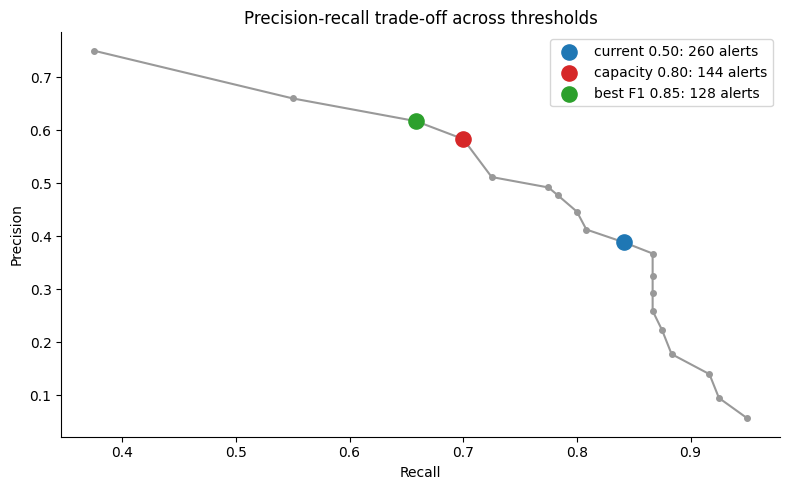

Recommendation: set the threshold to 0.80 -> 144 alerts (within the 150 cap), recall 70%, precision 58%, vs the current 0.50 giving 260 alerts (recall 84%, precision 39%).


In [5]:

rows = []
# TODO 1
y = tx.is_fraud.values == 1
for th in np.round(np.arange(0.05, 0.951, 0.05), 2):
    flagged_ = tx.detector_score.values >= th
    tp = int((flagged_ & y).sum()); fp = int((flagged_ & ~y).sum()); fn = int((~flagged_ & y).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    rows.append(dict(threshold=th, alerts=int(flagged_.sum()), TP=tp, FP=fp, FN=fn, precision=prec, recall=rec, F1=f1))

pr = pd.DataFrame(rows)
display(pr.round(3))

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="0.6", ms=4)
for name, r, col in [("current 0.50", current, "C0"), (f"capacity {capacity_choice.threshold:.2f}", capacity_choice, "C3"), (f"best F1 {best_f1.threshold:.2f}", best_f1, "C2")]:
    ax.scatter(r.recall, r.precision, s=120, color=col, zorder=3, label=f"{name}: {int(r.alerts)} alerts")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall trade-off across thresholds"); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: set the threshold to {capacity_choice.threshold:.2f} -> {int(capacity_choice.alerts)} alerts (within the 150 cap), "
      f"recall {capacity_choice.recall:.0%}, precision {capacity_choice.precision:.0%}, vs the current 0.50 giving {int(current.alerts)} alerts "
      f"(recall {current.recall:.0%}, precision {current.precision:.0%}).")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The **Head of Fraud Ops** should make that call, with the model only supplying the trade-off curve. The model can compute precision, recall and F1, but it cannot know the real costs: how much a missed fraud costs compared with an investigator's hour or an annoyed customer, or that the team can review only 150 alerts. F1 also weights precision and recall equally, which is a statistical convenience and not a business decision. Here the capacity choice (0.80: 144 alerts, recall 70%, precision 58%) and the best-F1 choice (0.85: 128 alerts, recall 66%) have almost identical F1 (0.636 vs 0.637), so the human should spend the spare capacity on catching 5 more frauds. Visual analytics keeps the human in the loop because steering a parameter against constraints and context the model does not have is exactly what the interactive view (here, the marked points on the precision-recall curve) is for.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:

# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig1 = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                  color_discrete_map={"confirmed fraud": "crimson", "legitimate": "lightgrey"},
                  hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                              "distance_from_home_km": ":.0f", "detector_score": ":.2f", "timestamp": False, "amount_inr": ":,.0f", "label": False},
                  title=f"{len(flagged)} flagged transactions (score >= 0.3): hover for details, drag to select")
fig1.update_layout(dragmode="select", xaxis_title="Time", yaxis_title="Amount (INR, log)")
fig1.show()

# TODO 2
fig2 = px.sunburst(tx, path=["city", "merchant_category"], color="is_fraud", color_continuous_scale="Reds",
                   title="Drill down: city -> merchant category (size = transactions, colour = fraud rate)")
fig2.update_coloraxes(colorbar_title="Fraud rate")
fig2.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ A tooltip reveals one point at a time, so to get an overview of 400 flagged cases the investigator would have to hover over each point and remember what they saw earlier, which overloads working memory and hides any pattern across cases. It also gives no summary (how many are fraud, where, when). The **city × day heatmap** from Task 1 (and the linked views from Task 2) fix that by showing all cases aggregated at once, so the tooltip is then used only for details on the cells or points that stand out. The sunburst gives the same kind of overview for city and category.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

In window: 107 txns, 40 fraud (37.4%) | outside: 1.48% | chi-square p = 1.06e-136
Pune, days 18-20 (window)    n=  107  fraud rate = 37.38%
Pune, other days             n=  593  fraud rate = 1.85%
Other cities, days 18-20     n=  457  fraud rate = 0.44%
Rest                         n= 4363  fraud rate = 1.54%


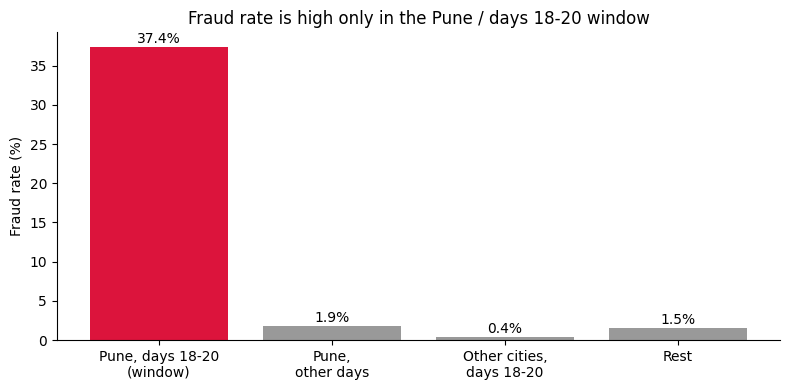

Verdict: SUPPORTED as a localized burst - 37% fraud rate in the window vs 1.9% for Pune on other days and 0.4% for other cities on the same days (p = 1.1e-136). But the 40 frauds hit 40 different customers, so this shows a concentrated attack, not who was behind it.


In [7]:

from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# H: a localized fraud burst hit PUNE on DAYS 18-20 (a ring would raise the fraud rate there far above every comparison group)
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p, dof, _ = chi2_contingency(ct)
rate_in, rate_out = tx.is_fraud[in_window].mean(), tx.is_fraud[~in_window].mean()
print(f"In window: {int(in_window.sum())} txns, {int(tx.is_fraud[in_window].sum())} fraud ({rate_in:.1%}) | outside: {rate_out:.2%} | chi-square p = {p:.2e}")

# TODO 3
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = (tx.city != "Pune") & ~tx.day.between(18, 20)
groups = {"Pune, days 18-20\n(window)": in_window, "Pune,\nother days": same_city_other_days,
          "Other cities,\ndays 18-20": other_cities_same_days, "Rest": rest}
rates = {k: tx.is_fraud[m].mean() for k, m in groups.items()}
for k, m in groups.items(): print(f"{k.replace(chr(10), ' '):28s} n={int(m.sum()):5d}  fraud rate = {rates[k]:.2%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(list(rates.keys()), [v * 100 for v in rates.values()], color=["crimson", "0.6", "0.6", "0.6"])
for b_, v in zip(bars, rates.values()): ax.text(b_.get_x() + b_.get_width() / 2, v * 100 + 0.5, f"{v:.1%}", ha="center")
ax.set_ylabel("Fraud rate (%)"); ax.set_title("Fraud rate is high only in the Pune / days 18-20 window")

plt.tight_layout(); plt.show()

# TODO 5
cust = tx[in_window & (tx.is_fraud == 1)].customer_id.nunique()
print(f"Verdict: SUPPORTED as a localized burst - {rate_in:.0%} fraud rate in the window vs {rates['Pune,\nother days']:.1%} for Pune on other days and "
      f"{rates['Other cities,\ndays 18-20']:.1%} for other cities on the same days (p = {p:.1e}). "
      f"But the {int(tx.is_fraud[in_window].sum())} frauds hit {cust} different customers, so this shows a concentrated attack, not who was behind it.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ Both searches could have killed the hypothesis, but in different ways. If **Pune on other days** had also had a high fraud rate, the burst would not be a time-limited ring but a persistent Pune problem such as a compromised terminal or merchant, or a biased detector. If **other cities on days 18-20** had also spiked, it would be a nationwide time-limited event (a data breach, a sale day, or a change in the detector or labelling) rather than something centred on Pune. Neither happened: Pune on other days was 1.85% and other cities on days 18-20 were 0.44%, against 37.4% in the window. That supports a localized burst, but 40 frauds on 40 different customers cannot show who was behind it.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ Last month PayKart had 120 confirmed frauds in 5,520 transactions (2.2%), and 40 of them (a third) were concentrated in Pune on days 18-20, where the fraud rate was 37% against about 1.5% elsewhere. I recommend raising the detector threshold from 0.50 to 0.80: it produces 144 alerts, within the 150-alert capacity (0.50 gives 260), while keeping 70% recall at 58% precision, and since the best-F1 threshold (0.85) is nearly identical on F1 but catches fewer frauds, the final trade-off is the Head of Fraud Ops's decision, not the model's (human in the loop). The first interactive view to build is the city × day overview with linked brushing, because overview first lets investigators spot a burst like Pune 18-20 before any alert list, and brushing then shows what those cases have in common; the filter slider will also stay within the 0.1 s budget on 50M rows only with pre-aggregation or skipping. Finally, add the feedback loop (Slide 51) so that investigators' confirmed labels on every reviewed alert, including the Pune cases, are fed back to retrain and re-tune the detector and threshold next month.